In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import warnings
from scipy.linalg import expm
from scipy.optimize import least_squares


# Importa as bibliotecas desenvolvida para o projeto
import quantum_tomography as qt
import entropyreg as er

In [3]:
# Funções criadas pela IA que ainda preciso entender o pq foram feitas
def rho_a_partir_de_u(u, H, Q_list, epsilon):
    operador = sum(u_i * Q_i for u_i, Q_i in zip(u, Q_list)) - H
    return expm(operador / epsilon)


def normalizar_rho(rho):
    tr = np.trace(rho).real
    if not np.isfinite(tr) or tr <= 0:
        raise ValueError("A exponencial não produziu um traço positivo e finito.")
    return rho / tr


def entropia_von_neumann(rho):
    rho_h = (rho + rho.conj().T) / 2
    autovalores = np.linalg.eigvalsh(rho_h)
    autovalores = np.clip(autovalores, 0.0, None)
    positivos = autovalores[autovalores > 1e-14]
    return float(-np.sum(positivos * np.log(positivos)))


def estado_gibbs(H, beta):
    """Estado térmico exp(-beta H)/Z. Função auxiliar deste notebook."""
    return qt.QuantState(normalizar_rho(expm(-beta * H)))


def montar_observaveis_pauli(n_qubits):
    nomes = ["I" * n_qubits] + qt.pauli_basis_strings(n_qubits)
    matrizes = [qt.pauli_string_to_matrix(nome) for nome in nomes]
    return nomes, matrizes


def rodar_estocastico_com_historico(H, Q_list, q, epsilon, k, lr,
                                    max_iters=5000, tol=1e-6, seed=0,
                                    check_every=10):
    """
    Atualiza k coordenadas sorteadas. A cada check_every passos, calcula
    a norma do gradiente completo para avaliar/parar o método.
    """
    rng = np.random.default_rng(seed)
    u = np.zeros(len(q), dtype=float)
    m = len(q)
    historico = [[0, np.linalg.norm(er.dual_gradient(u, H, Q_list, q, epsilon))]]
    inicio = time.perf_counter()

    for t in range(1, max_iters + 1):
        grad_parcial, _ = er.stochastic_gradient(
            u, H, Q_list, q, epsilon, rng=rng, k=k
        )
        if not np.all(np.isfinite(grad_parcial)):
            break
        u -= lr * grad_parcial

        if t % check_every == 0:
            # k=m faz stochastic_gradient devolver todas as componentes:
            # portanto, aqui temos o gradiente completo.
            grad_completo, _ = er.stochastic_gradient(
                u, H, Q_list, q, epsilon, rng=rng, k=m
            )
            norma = np.linalg.norm(grad_completo)
            historico.append([t, norma])
            if np.isfinite(norma) and norma < tol:
                break

    tempo = time.perf_counter() - inicio
    return u, t, np.asarray(historico), tempo

Sanity check, verificação de que ambos os métodos funcionam para um mesmo problema com os mesmos parâmetros.

In [3]:
Q = [np.eye(2), qt.pauli_string_to_matrix("X"), qt.pauli_string_to_matrix("Y")]
q = [1, 0.7, 0.4]
H = 0
epsilon = 1

# Teste com Gradient Ascent
pistar_data = er.reconstruct_pi(H, Q, q, epsilon, lr=1, max_iters=10000, tol=1e-6)
pistar = pistar_data[0]

print("Com o método de Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(np.trace(pistar), np.trace(pistar @ Q[1]), np.trace(pistar @ Q[2]))
print("Número de iterações: ", pistar_data[2])
print("Matriz reconstruída pi*:")
print(pistar)

# Teste com Stochastic Gradient Ascent
stocpistar_data = er.reconstruct_spi(H, Q, q, epsilon, max_iters=5000, lr=1, tol=1e-6, k=2, count_it=1)
stocpistar, stoc_u_opt, stoc_n_it, stoc_pi_grad  = stocpistar_data
stoc_grad_data = np.array(stoc_pi_grad)

print("Com o método de Stochastic Gradient Ascent:")
print("Valores das médias com os observáveis I, Sigma_x, Sigma_y:" )
print(np.trace(stocpistar), np.trace(stocpistar @ Q[1]), np.trace(stocpistar @ Q[2]))
print("iterações:", stoc_n_it)
print("Matriz reconstruída pi*:")
print(stocpistar)


Com o método de Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000008181897577-4.1777418156342424e-17j) (0.7000002472614089-2.7755575615628914e-17j) (0.4000001412922337+0j)
Número de iterações:  56
Matriz reconstruída pi*:
[[0.50000041+4.80325509e-18j 0.35000012-2.00000071e-01j]
 [0.35000012+2.00000071e-01j 0.50000041-4.65806732e-17j]]
Com o método de Stochastic Gradient Ascent:
Valores das médias com os observáveis I, Sigma_x, Sigma_y:
(1.0000000001282152-1.0194436133805656e-17j) (0.6999999783829212-5.551115123125783e-17j) (0.3999999874537122+5.551115123125783e-17j)
iterações: 100
Matriz reconstruída pi*:
[[0.5       +2.53539514e-17j 0.34999999-1.99999994e-01j]
 [0.34999999+1.99999994e-01j 0.5       -3.55483875e-17j]]


Definimos agora um estado alvo de 3 qubits para realizar a comparação entre os métodos, e então, escolhermos um para prosseguir nossa abordagem.

In [4]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, rank=4, seed=17)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)
epsilon = 1.0

print(estado_alvo)
print("Número de observáveis:", len(Q))
print("Traço do estado-alvo:", np.trace(estado_alvo.rho).real)
print("Autovalores do estado-alvo:", np.linalg.eigvalsh(estado_alvo.rho))

<QuantState (3 qubits, Misto (posto 4), pureza=0.336)>
Número de observáveis: 64
Traço do estado-alvo: 1.0
Autovalores do estado-alvo: [-4.88560586e-17 -2.24320419e-17  3.35882833e-18  3.35699553e-17
  9.90608868e-02  1.26475398e-01  3.13921218e-01  4.60542498e-01]


In [5]:
lr_comparacao = 0.5
tol = 1e-6
check_every = 10
max_iters = 100000

# Gradient Descent completo
t0 = time.perf_counter()
gd_data = er.gradient_descent(
    H, Q, q, epsilon, max_iters=max_iters, lr=lr_comparacao, tol=tol
)
tempo_gd = time.perf_counter() - t0
u_gd, it_gd, us_gd, grad_gd = gd_data

# Método estocástico com k coordenadas por iteração
t0 = time.perf_counter()
u_st, it_st, hist_st = er.sgd(
    H, Q, q, epsilon, k=len(Q)//2, lr=lr_comparacao,
    n_iter=max_iters, tol=tol, seed=0,
    check_every=check_every, count_it=check_every
)
tempo_st = time.perf_counter() - t0

rho_gd = normalizar_rho(rho_a_partir_de_u(u_gd, H, Q, epsilon))
rho_st = normalizar_rho(rho_a_partir_de_u(u_st, H, Q, epsilon))

print("Gradient Descent")
print("iterações:", it_gd, "| tempo (s):", round(tempo_gd, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_gd, estado_alvo.rho))

print("\nMétodo estocástico")
print("iterações:", it_st, "| tempo (s):", round(tempo_st, 4))
print("norma final do gradiente:", np.linalg.norm(er.dual_gradient(u_st, H, Q, q, epsilon)))
print("fidelidade:", qt.fidelidade(rho_st, estado_alvo.rho))

Gradient Descent
iterações: 100000 | tempo (s): 16.7513
norma final do gradiente: 1.4139716064896302e-05
fidelidade: 0.9999900226908442

Método estocástico
iterações: 100000 | tempo (s): 15.8972
norma final do gradiente: 3.024788892237474e-05
fidelidade: 0.9999799623257319


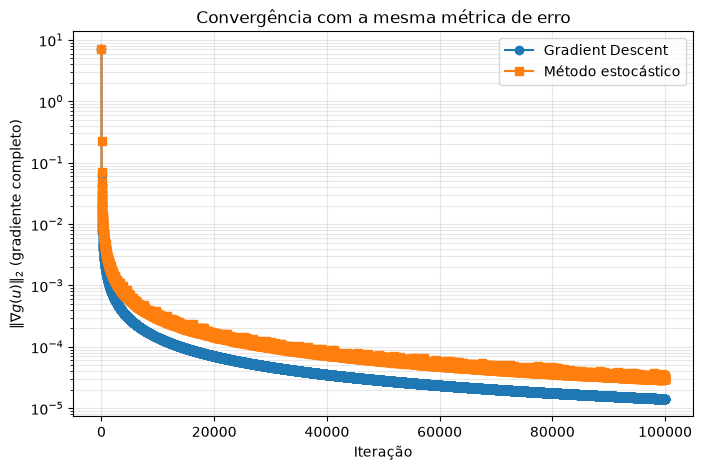

In [6]:
# O GD registra todos os passos; selecionamos os mesmos instantes usados no SGD.
hist_gd = np.asarray(grad_gd)
hist_gd = hist_gd[hist_gd[:, 0] % check_every == 0]
grad_gd_final = np.linalg.norm(er.dual_gradient(u_gd, H, Q, q, epsilon))
if hist_gd[-1, 0] != it_gd:
    hist_gd = np.vstack([hist_gd, [it_gd, grad_gd_final]])

hist_st = np.asarray(hist_st)
grad_inicial = np.linalg.norm(
    er.dual_gradient(np.zeros(len(q)), H, Q, q, epsilon)
)
hist_st = np.vstack([[0, grad_inicial], hist_st])

plt.figure(figsize=(8, 5))
plt.semilogy(hist_gd[:, 0], hist_gd[:, 1], "o-", label="Gradient Descent")
plt.semilogy(hist_st[:, 0], hist_st[:, 1], "s-", label="Método estocástico")
plt.xlabel("Iteração")
plt.ylabel(r"$\|\nabla g(u)\|_2$ (gradiente completo)")
plt.title("Convergência com a mesma métrica de erro")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()

Selecionamos então o stochastic method pois ele aparenta funcionar melhor na questão de memória para problemas com dimensionalidade maior. Desse modo, agora vamos definir um estado arbitrário alvo, e verificar a convergência do método variando tanto o learning rate como o epsilon(correspondente à temperatura).

In [7]:
n_qubits = 3
estado_alvo = qt.random_mixture_of_pures(dim=2**n_qubits, seed=35)

nomes_obs, Q = montar_observaveis_pauli(n_qubits)
q = qt.measure_observables(estado_alvo, nomes_obs)
H = np.zeros((2**n_qubits, 2**n_qubits), dtype=complex)

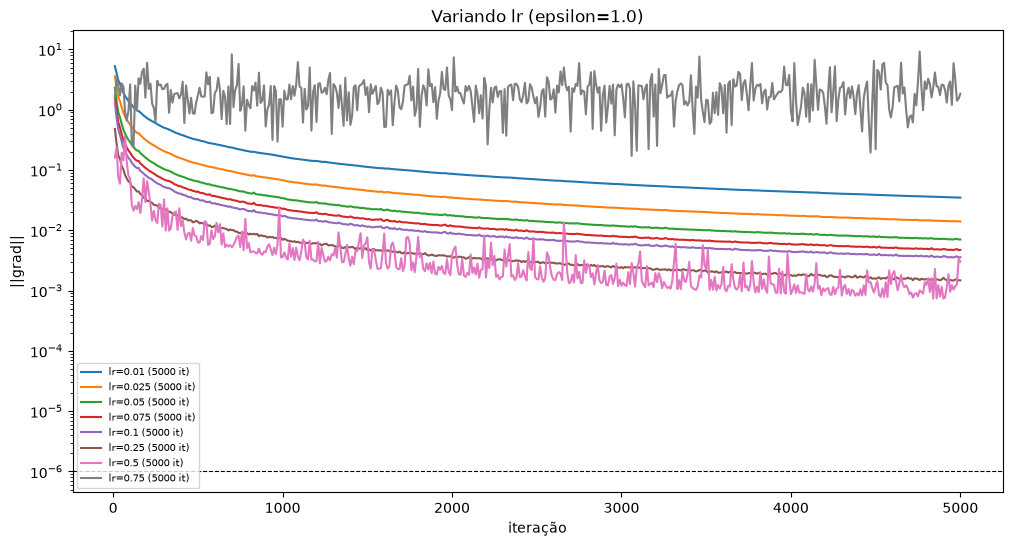

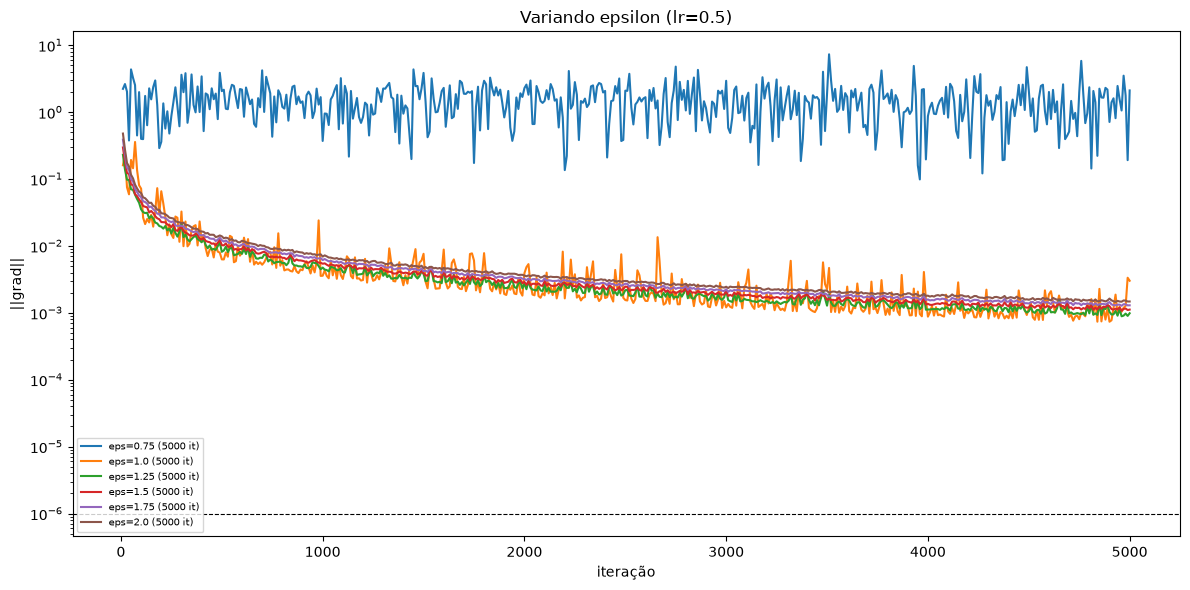

In [9]:
tol_fix = 1e-6
check_every_fix = 50
max_iters_fix = 5000

seeds = range(5)
epsilon_values = [0.75, 1.0, 1.25, 1.5, 1.75, 2.0]
lr_values = [0.01,0.025, 0.05, 0.075, 0.1, 0.25, 0.5, 0.75]

lr_fix = 0.5
epsilon_fix = 1.0

k = len(Q) // 2


def rodar(lr, epsilon):
    u, n_it, hist = er.sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters_fix,
                        tol=tol_fix, seed=0, check_every=check_every_fix, count_it=10)
    hist = np.array(hist)
    return hist[:, 0], hist[:, 1], n_it


fig1, ax1 = plt.subplots(figsize=(12, 6))
fig2, ax2 = plt.subplots(figsize=(12, 6))

for lr in lr_values:
    t, g, n_it = rodar(lr, epsilon_fix)
    ax1.semilogy(t, g, label=f"lr={lr} ({n_it} it)")
ax1.set_title(f"Variando lr (epsilon={epsilon_fix})")

for eps in epsilon_values:
    t, g, n_it = rodar(lr_fix, eps)
    ax2.semilogy(t, g, label=f"eps={eps} ({n_it} it)")
ax2.set_title(f"Variando epsilon (lr={lr_fix})")

for a in [ax1, ax2]:
    a.axhline(tol_fix, color="k", ls="--", lw=0.8)
    a.set_xlabel("iteração")
    a.set_ylabel("||grad||")
    a.legend(fontsize=7)

plt.tight_layout()
plt.show()

Agora, o experimentos que faremos é definir uma lista de diferentes tipos de estados, escolher parâmetros que façam sentido para a resolução de cada um deles, e verificar a convergência do método com a regularização entrópica para cada um desses tipos de estado.

lr=0.25, epsilon=1.25, k=32/64, count_it=25, max_iters=10000

estado              pureza posto  iters   ||grad||   Tr(pi)  fidelidade
Puro                1.0000     1  10000   9.72e-04   1.0008    0.999122
Mistura de puros    0.3129     4  10000   7.38e-04   1.0004    0.999499
Gibbs (beta=1)      0.4785     8  10000   1.70e-05   1.0000    1.000000
Totalmente misto    0.1250     8    150   4.08e-09   1.0000    1.000000


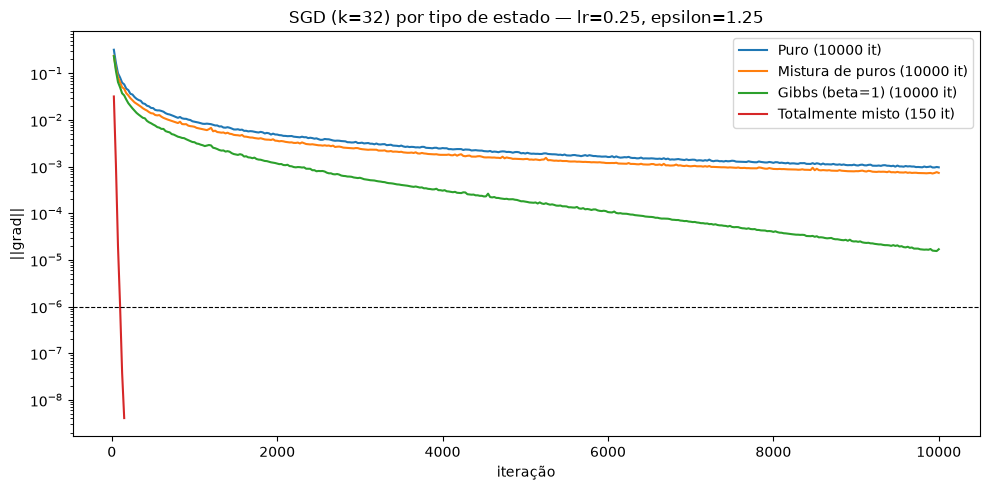

In [10]:
n_qubits = 3
dim = 2**n_qubits

lr, epsilon = 0.25, 1.25          # ajuste conforme os testes anteriores
tol = 1e-6
check_every = 50
max_iters = 10000
count_it = 25

# Observáveis: as 4^n Paulis COM a identidade (a identidade fixa Tr(pi) = 1)
nomes_obs = qt.pauli_basis_strings(n_qubits, include_identity=True)
Q = [qt.pauli_string_to_matrix(s) for s in nomes_obs]
H = np.zeros((dim, dim), dtype=complex)     # H do problema de reconstrução
k = len(Q) // 2                              # batch = metade das coordenadas

# ----------------------------------------------------------------------
# Estados alvo
# ----------------------------------------------------------------------
def hamiltoniano_ising(n, g=1.0):
    """H_fis = - sum Z_i Z_{i+1} - g sum X_i  (apenas para gerar o estado de Gibbs)."""
    Hf = np.zeros((2**n, 2**n), dtype=complex)
    for i in range(n - 1):
        s = ["I"] * n; s[i] = s[i + 1] = "Z"
        Hf -= qt.pauli_string_to_matrix("".join(s))
    for i in range(n):
        s = ["I"] * n; s[i] = "X"
        Hf -= g * qt.pauli_string_to_matrix("".join(s))
    return Hf

def estado_gibbs(Hf, beta):
    rho = expm(-beta * Hf)
    return qt.QuantState(rho / np.trace(rho).real)

estados = {
    "Puro":              qt.random_pure_state(dim, seed=35),
    "Mistura de puros":  qt.random_mixture_of_pures(dim, rank=4, seed=35),
    "Gibbs (beta=1)":    estado_gibbs(hamiltoniano_ising(n_qubits), beta=1.0),
    "Totalmente misto":  qt.maximally_mixed_state(dim),
}

# ----------------------------------------------------------------------
# SGD em cada estado
# ----------------------------------------------------------------------
resultados = {}
print(f"lr={lr}, epsilon={epsilon}, k={k}/{len(Q)}, count_it={count_it}, max_iters={max_iters}\n")
print(f"{'estado':<18}{'pureza':>8}{'posto':>6}{'iters':>7}{'||grad||':>11}{'Tr(pi)':>9}{'fidelidade':>12}")

for nome, estado in estados.items():
    q = qt.measure_observables(estado, nomes_obs)
    u, n_it, hist = er.sgd(H, Q, q, epsilon, k=k, lr=lr, n_iter=max_iters, tol=tol,
                           seed=0, check_every=check_every, count_it=count_it)
    hist = np.array(hist)

    pi = expm((sum(u_i * Q_i for u_i, Q_i in zip(u, Q)) - H) / epsilon)
    g_final = np.linalg.norm(er.dual_gradient(u, H, Q, q, epsilon))
    tr = np.real(np.trace(pi))
    fid = qt.fidelidade(estado.rho, pi / tr) if np.isfinite(tr) else np.nan

    resultados[nome] = (hist[:, 0], hist[:, 1], n_it)
    print(f"{nome:<18}{estado.purity:8.4f}{estado.rank:6d}{n_it:7d}{g_final:11.2e}{tr:9.4f}{fid:12.6f}")

# ----------------------------------------------------------------------
# Gráfico
# ----------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
for nome, (t, g, n_it) in resultados.items():
    ok = np.isfinite(g)
    ax.semilogy(t[ok], g[ok], label=f"{nome} ({n_it} it)")
ax.axhline(tol, color="k", ls="--", lw=0.8)
ax.set_xlabel("iteração")
ax.set_ylabel("||grad||")
ax.set_title(f"SGD (k={k}) por tipo de estado — lr={lr}, epsilon={epsilon}")
ax.legend()
fig.tight_layout()
plt.show()

Um dos testes que parece fazer sentido, é aumentar a dimensionalidade do problema e ver até que ponto a máquina é capaz de resolver, vamos definir o tipo de estado (e parâmetros que pareçam razoáveis) que pelos testes feitos, parece ser o que melhor converge, para determinar um upper boundary para essa questão.

In [ ]:
LETRAS = "IXYZ"


# ----------------------------------------------------------------------
# Paulis geradas sob demanda
# ----------------------------------------------------------------------
def nome_pauli(idx, n):
    """Índice 0..4^n-1 -> string de Pauli (mesma ordem de qt.pauli_basis_strings com identidade)."""
    s = []
    for _ in range(n):
        s.append(LETRAS[idx & 3])
        idx >>= 2
    return "".join(reversed(s))


def matriz_pauli(idx, n):
    return qt.pauli_string_to_matrix(nome_pauli(idx, n))


def medidas_pauli(rho, n):
    """q_i = Tr(Q_i rho) para todas as 4^n Paulis, sem guardar as matrizes."""
    q = np.empty(4**n)
    rho_T = rho.T
    for i in range(4**n):
        q[i] = np.real(np.sum(matriz_pauli(i, n) * rho_T))
    return q


def grad_completo(pi, q, n):
    """Gradiente completo: Tr(Q_i pi) - q_i para as 4^n coordenadas (em loop)."""
    g = np.empty(4**n)
    pi_T = pi.T
    for i in range(4**n):
        g[i] = np.real(np.sum(matriz_pauli(i, n) * pi_T)) - q[i]
    return g


# ----------------------------------------------------------------------
# SGD com memória reduzida
# ----------------------------------------------------------------------
def sgd_mem(H, q, n, epsilon, k, lr=1.0, n_iter=10000, tol=1e-6, seed=0,
            check_every=500, count_it=500):
    """
    Partida normalizada: u = 0 exceto u_I = -eps*ln(2^n)  (Tr(pi)=1 no início).
    Retorna u, iterações feitas, histórico [[t, ||grad||], ...] e A final.
    """
    rng = np.random.default_rng(seed)
    d, m = 2**n, 4**n
    u = np.zeros(m)
    u[0] = -epsilon * np.log(d)
    A = u[0] * np.eye(d, dtype=complex) - H
    grad_data = []

    for t in range(1, n_iter + 1):
        pi = expm(A / epsilon)
        idx = rng.choice(m, size=k, replace=False)

        dA = np.zeros_like(A)
        for i in idx:
            Qi = matriz_pauli(i, n)                      # gerada e descartada
            g = np.real(np.sum(Qi * pi.T)) - q[i]
            u[i] -= lr * g
            dA += (-lr * g) * Qi
        A += dA

        if t % count_it == 0 or t % check_every == 0:
            gn = np.linalg.norm(grad_completo(expm(A / epsilon), q, n))
            if t % count_it == 0:
                grad_data.append([t, gn])
            if not np.isfinite(gn):                      # divergiu: não adianta continuar
                return u, t, grad_data, A
            if t % check_every == 0 and gn < tol:
                return u, t, grad_data, A

    return u, n_iter, grad_data, A


# ----------------------------------------------------------------------
# Estado de Gibbs
# ----------------------------------------------------------------------
def hamiltoniano_ising(n, g=1.0):
    """H_fis = - sum Z_i Z_{i+1} - g sum X_i  (só para gerar o estado de Gibbs)."""
    Hf = np.zeros((2**n, 2**n), dtype=complex)
    for i in range(n - 1):
        s = ["I"] * n; s[i] = s[i + 1] = "Z"
        Hf -= qt.pauli_string_to_matrix("".join(s))
    for i in range(n):
        s = ["I"] * n; s[i] = "X"
        Hf -= g * qt.pauli_string_to_matrix("".join(s))
    return Hf


def rho_gibbs(n, beta):
    rho = expm(-beta * hamiltoniano_ising(n))
    return rho / np.trace(rho).real


def fmt_bytes(b):
    for u in ["B", "KB", "MB", "GB", "TB"]:
        if b < 1024 or u == "TB":
            return f"{b:.0f} {u}"
        b /= 1024


# ----------------------------------------------------------------------
# Experimento
# ----------------------------------------------------------------------

n_list = [3, 4, 5, 6, 7]
beta = 1.0
epsilon = 1.0
lr = 0.5                 # com k pequeno dá para usar lr maior (limite ~ 2*eps)
tol = 1e-6
max_iters = 100000
check_every = 500
count_it = 500
H = None                 # H do problema de reconstrução = 0 (definido por n abaixo)

print(f"Gibbs beta={beta} | lr={lr} eps={epsilon} | k = 2^n | "
        f"check_every={check_every} count_it={count_it} max_iters={max_iters}\n")
print(f"{'n':>2}{'4^n':>8}{'k':>6}{'Q evitada':>11}{'iters':>7}{'||grad||':>11}"
        f"{'fidelidade':>12}{'t_q(s)':>8}{'t_sgd(s)':>10}")

curvas = {}
for n in n_list:
    d = 2**n
    k = 2**n
    H = np.zeros((d, d), dtype=complex)
    rho = rho_gibbs(n, beta)

    t0 = time.perf_counter()
    q = medidas_pauli(rho, n)
    t_q = time.perf_counter() - t0

    t0 = time.perf_counter()
    u, n_it, hist, A = sgd_mem(H, q, n, epsilon, k, lr=lr, n_iter=max_iters, tol=tol,
                                seed=0, check_every=check_every, count_it=count_it)
    t_sgd = time.perf_counter() - t0

    pi = expm(A / epsilon)
    g_final = np.linalg.norm(grad_completo(pi, q, n))
    fid = qt.fidelidade(rho, pi / np.real(np.trace(pi))) if np.isfinite(g_final) else np.nan
    curvas[n] = np.array(hist)

    print(f"{n:>2}{4**n:>8}{k:>6}{fmt_bytes(16 * 16**n):>11}{n_it:>7}{g_final:>11.2e}"
            f"{fid:>12.6f}{t_q:>8.1f}{t_sgd:>10.1f}")

fig, ax = plt.subplots(figsize=(9, 5))
for n, h in curvas.items():
    ok = np.isfinite(h[:, 1])
    ax.semilogy(h[ok, 0], h[ok, 1], "o-", ms=3, label=f"n={n} (k={2**n})")
ax.axhline(tol, color="k", ls="--", lw=0.8)
ax.set_xlabel("iteração"); ax.set_ylabel("||grad||")
ax.set_title(f"SGD de memória reduzida — Gibbs beta={beta}")
ax.legend()
fig.tight_layout()
plt.show()

Gibbs beta=1.0 | lr=0.5 eps=1.0 | k = 2^n | check_every=500 count_it=500 max_iters=100000

 n     4^n     k  Q evitada  iters   ||grad||  fidelidade  t_q(s)  t_sgd(s)
 3      64     8      64 KB  25500   9.42e-07    1.000000     0.0       4.1
 4     256    16       1 MB 100000   2.74e-05    1.000000     0.0     117.1
 5    1024    32      16 MB 100000   1.89e-04    0.999981     0.1     258.0
 6    4096    64     256 MB 100000   5.93e-04    0.999886     0.2     707.6
 7   16384   128       4 GB 100000   1.44e-03    0.999550     1.7    3400.7


KeyboardInterrupt: 

In [18]:
import sys
tb = sys.last_traceback
frame = None
while tb is not None:
    if tb.tb_frame.f_code.co_name == "sgd_mem":
        frame = tb.tb_frame
    tb = tb.tb_next

loc = frame.f_locals
hist = np.array(loc["grad_data"])
print("parou na iteração", loc["t"], "| pontos no histórico:", len(hist))


parou na iteração 47030 | pontos no histórico: 94


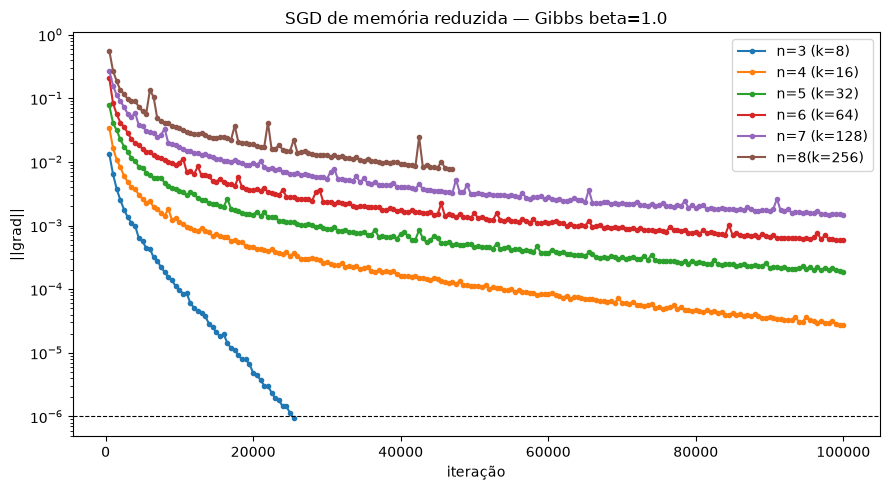

In [16]:
fig, ax = plt.subplots(figsize=(9, 5))
for n, h in curvas.items():
    ok = np.isfinite(h[:, 1])
    ax.semilogy(h[ok, 0], h[ok, 1], "o-", ms=3, label=f"n={n} (k={2**n})")
ax.semilogy(hist[:, 0], hist[:, 1], "o-", ms=3, label = f"n={8}(k={2**8})")
ax.axhline(tol, color="k", ls="--", lw=0.8)
ax.set_xlabel("iteração"); ax.set_ylabel("||grad||")
ax.set_title(f"SGD de memória reduzida — Gibbs beta={beta}")
ax.legend()
fig.tight_layout()
plt.show()

Gibbs beta=1.0 | lr=0.5 eps=1.0 | k = 2^n | check_every=500 count_it=500 max_iters=10000

 n     4^n     k  Q evitada  iters   ||grad||  fidelidade  t_q(s)  t_sgd(s)
 3      64     8      64 KB   4000   9.95e-04    0.999975     0.0       0.6
 4     256    16       1 MB  10000   1.14e-03    0.999878     0.0       4.4
 5    1024    32      16 MB  10000   3.49e-03    0.999234     0.1      29.4
 6    4096    64     256 MB  10000   9.58e-03    0.997247     0.2      75.3
 7   16384   128       4 GB  10000   1.70e-02    0.992596     1.8     368.3
 8   65536   256      64 GB  10000   3.46e-02    0.982280    22.4    2295.8


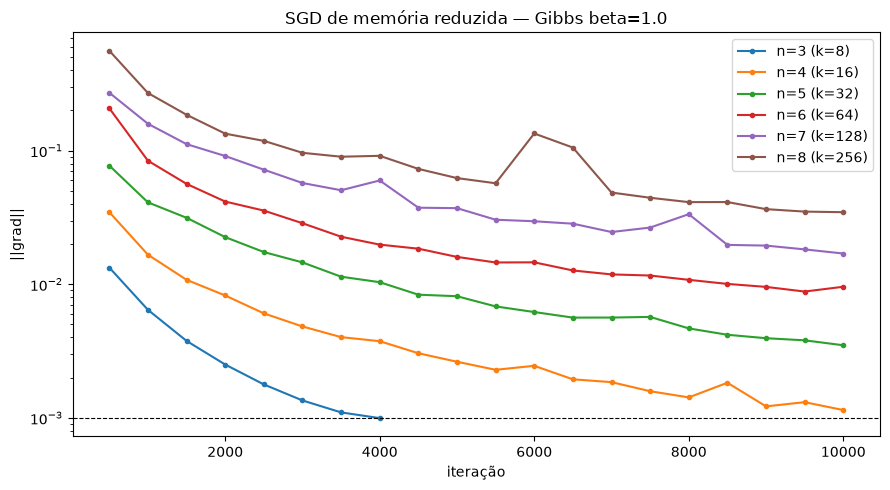

In [17]:
n_list = [3, 4, 5, 6, 7, 8]
beta = 1.0
epsilon = 1.0
lr = 0.5                 # com k pequeno dá para usar lr maior (limite ~ 2*eps)
tol = 1e-3
max_iters = 10000
check_every = 500
count_it = 500
H = None                 # H do problema de reconstrução = 0 (definido por n abaixo)

print(f"Gibbs beta={beta} | lr={lr} eps={epsilon} | k = 2^n | "
        f"check_every={check_every} count_it={count_it} max_iters={max_iters}\n")
print(f"{'n':>2}{'4^n':>8}{'k':>6}{'Q evitada':>11}{'iters':>7}{'||grad||':>11}"
        f"{'fidelidade':>12}{'t_q(s)':>8}{'t_sgd(s)':>10}")

curvas = {}
for n in n_list:
    d = 2**n
    k = 2**n
    H = np.zeros((d, d), dtype=complex)
    rho = rho_gibbs(n, beta)

    t0 = time.perf_counter()
    q = medidas_pauli(rho, n)
    t_q = time.perf_counter() - t0

    t0 = time.perf_counter()
    u, n_it, hist, A = sgd_mem(H, q, n, epsilon, k, lr=lr, n_iter=max_iters, tol=tol,
                                seed=0, check_every=check_every, count_it=count_it)
    t_sgd = time.perf_counter() - t0

    pi = expm(A / epsilon)
    g_final = np.linalg.norm(grad_completo(pi, q, n))
    fid = qt.fidelidade(rho, pi / np.real(np.trace(pi))) if np.isfinite(g_final) else np.nan
    curvas[n] = np.array(hist)

    print(f"{n:>2}{4**n:>8}{k:>6}{fmt_bytes(16 * 16**n):>11}{n_it:>7}{g_final:>11.2e}"
            f"{fid:>12.6f}{t_q:>8.1f}{t_sgd:>10.1f}")

fig, ax = plt.subplots(figsize=(9, 5))
for n, h in curvas.items():
    ok = np.isfinite(h[:, 1])
    ax.semilogy(h[ok, 0], h[ok, 1], "o-", ms=3, label=f"n={n} (k={2**n})")
ax.axhline(tol, color="k", ls="--", lw=0.8)
ax.set_xlabel("iteração"); ax.set_ylabel("||grad||")
ax.set_title(f"SGD de memória reduzida — Gibbs beta={beta}")
ax.legend()
fig.tight_layout()
plt.show()

Outro teste que me pareceu interessante fazer foi pegar um estado alvo com dimensionalidade alta e verificar a partir de alguma medida de distância entre estados, como o método responde a medida que aumentamos o número de observáveis que sabemos as medidas, para assim determinar (claro, de forma limitada) um limiar a partir de quando o estado encontrado é perto o "suficiente" do estado alvo

In [5]:
# =====================================================================
# Quantos observáveis precisamos medir para chegar perto do estado alvo?
#
# Requer as células anteriores do notebook (imports e funções auxiliares):
#   qt, er, np, plt, estado_gibbs, normalizar_rho, rho_a_partir_de_u,
#   montar_observaveis_pauli
# =====================================================================

# ---------------------------------------------------------------------
# 1) Parâmetros do teste
# ---------------------------------------------------------------------
n_list = [1, 2, 3, 4, 5]       # números de qubits
beta = 1.0                  # temperatura inversa do estado de Gibbs alvo
epsilon = 1.0               # regularização entrópica
lr = 0.25                   # learning rate (0.5 oscilou em n=4 com muitos observáveis)
tol = 1e-5                  # tolerância da norma do gradiente
max_iters = 5000
check_every = 50
seeds = range(3)            # cada seed sorteia uma ordem diferente de observáveis
limiar = 1e-2               # distância de traço que consideramos "perto o suficiente"


# ---------------------------------------------------------------------
# 2) Estado alvo: Gibbs de uma cadeia de Ising
#    ATENÇÃO: este H_gibbs serve APENAS para DEFINIR o estado alvo
#    rho = exp(-beta * H_gibbs) / Z. Ele não tem relação com o H do solver
#    (er.sgd), que continua sendo a matriz nula.
# ---------------------------------------------------------------------
def hamiltoniano_ising(n):
    """H_gibbs = - soma de Z_i Z_(i+1) - soma de X_i."""
    H_gibbs = np.zeros((2**n, 2**n), dtype=complex)
    for i in range(n - 1):                       # termos ZZ entre vizinhos
        s = ["I"] * n
        s[i] = s[i + 1] = "Z"
        H_gibbs -= qt.pauli_string_to_matrix("".join(s))
    for i in range(n):                           # termos X em cada qubit
        s = ["I"] * n
        s[i] = "X"
        H_gibbs -= qt.pauli_string_to_matrix("".join(s))
    return H_gibbs


# ---------------------------------------------------------------------
# 3) Para cada n e cada quantidade m de observáveis: roda o SGD e mede
#    a distância entre o estado reconstruído e o estado alvo
# ---------------------------------------------------------------------
resultados = {}   # (n, seed) -> lista de (m, distância de traço)

print(f"{'n':>2}{'m':>5}{'seed':>5}{'iters':>7}{'||grad||':>11}{'dist. traço':>13}{'fidelidade':>12}")

for n in n_list:
    d = 2**n
    H = np.zeros((d, d), dtype=complex)          # H do solver: nulo, como sempre

    # Estado alvo (objeto QuantState; a matriz densidade fica em estado_alvo.rho)
    estado_alvo = estado_gibbs(hamiltoniano_ising(n), beta)

    # Todos os 4^n observáveis de Pauli. O primeiro é a identidade (fixa Tr(pi) = 1).
    # Para n <= 4 são no máximo 256 matrizes 16x16 (~1 MB), então não há problema de memória.
    nomes_todos, Q_todos = montar_observaveis_pauli(n)

    # Passo de aumento: n=1 -> 2 em 2, n=2 -> 4 em 4, n=3 -> 8 em 8, n=4 -> 16 em 16
    passo = 2**n
    lista_m = list(range(passo, 4**n + 1, passo))

    for seed in seeds:
        # Ordem aleatória dos observáveis (menos a identidade, que fica sempre em primeiro).
        # Usar os PRIMEIROS m dessa ordem faz os conjuntos serem aninhados:
        # o conjunto com m=8 contém o de m=4, e assim por diante.
        rng = np.random.default_rng(seed)
        ordem = [0] + list(rng.permutation(np.arange(1, 4**n)))

        resultados[(n, seed)] = []
        for m in lista_m:
            # Seleciona só os m primeiros observáveis dessa ordem
            idx = ordem[:m]
            nomes = [nomes_todos[i] for i in idx]
            Q = [Q_todos[i] for i in idx]

            # "Medidas": valores esperados exatos desses observáveis no estado alvo
            q = qt.measure_observables(estado_alvo, nomes)

            # Ponto de partida: u = 0, exceto na identidade, que começa em -epsilon*ln(d).
            # Assim Tr(pi) começa valendo 1 (e não d). Com u = 0 puro, uma das seeds
            # (n=4) divergiu logo no começo, porque o traço de pi começa grande.
            u0 = np.zeros(m)
            u0[0] = -epsilon * np.log(d)

            # SGD com batch de metade dos observáveis (pelo menos 1)
            u, n_it, _ = er.sgd(H, Q, q, epsilon, k=max(1, m // 2), lr=lr,
                                n_iter=max_iters, tol=tol, seed=seed, u0=u0,
                                check_every=check_every)

            # Reconstrói o estado a partir de u e normaliza o traço para 1
            rho_rec = normalizar_rho(rho_a_partir_de_u(u, H, Q, epsilon))

            # Distâncias entre o estado reconstruído e o alvo
            dist = qt.trace_distance(estado_alvo.rho, rho_rec)
            fid = qt.fidelidade(estado_alvo.rho, rho_rec)
            grad_final = np.linalg.norm(er.dual_gradient(u, H, Q, q, epsilon))

            resultados[(n, seed)].append((m, dist))
            print(f"{n:>2}{m:>5}{seed:>5}{n_it:>7}{grad_final:>11.1e}{dist:>13.2e}{fid:>12.6f}")


# ---------------------------------------------------------------------
# 4) Limiar: menor m em que a distância de traço fica abaixo de `limiar`
# ---------------------------------------------------------------------
print(f"\nMenor m com distância de traço < {limiar}:")
for n in n_list:
    achados = []
    for seed in seeds:
        m_ok = [m for m, dist in resultados[(n, seed)] if dist < limiar]
        achados.append(m_ok[0] if m_ok else None)      # None = nunca chegou lá
    print(f"  n={n} (de {4**n} observáveis): {achados}  (um valor por seed)")





 n    m seed  iters   ||grad||  dist. traço  fidelidade
 1    2    0     50    1.1e-16     3.81e-01    0.824027
 1    4    0    350    3.3e-06     2.00e-06    1.000000
 1    2    1    350    2.8e-06     1.54e-06    1.000000
 1    4    1    350    2.4e-06     1.51e-06    1.000000
 1    2    2     50    5.6e-17     3.81e-01    0.824027
 1    4    2    350    4.6e-06     2.48e-06    1.000000
 2    4    0    250    3.0e-06     4.23e-01    0.764467
 2    8    0    400    4.9e-06     2.58e-01    0.905900
 2   12    0   1450    7.5e-06     5.91e-06    1.000000
 2   16    0   1700    9.9e-06     4.56e-06    1.000000
 2    4    1     50    0.0e+00     4.96e-01    0.633909
 2    8    1    250    1.0e-06     3.61e-01    0.765944
 2   12    1   1050    9.4e-06     1.34e-01    0.946425
 2   16    1   1800    7.6e-06     3.74e-06    1.000000
 2    4    2    100    3.3e-07     4.83e-01    0.634543
 2    8    2    250    6.9e-06     4.19e-01    0.760168
 2   12    2    500    3.9e-06     3.16e-01    0

KeyboardInterrupt: 

KeyError: (5, 2)

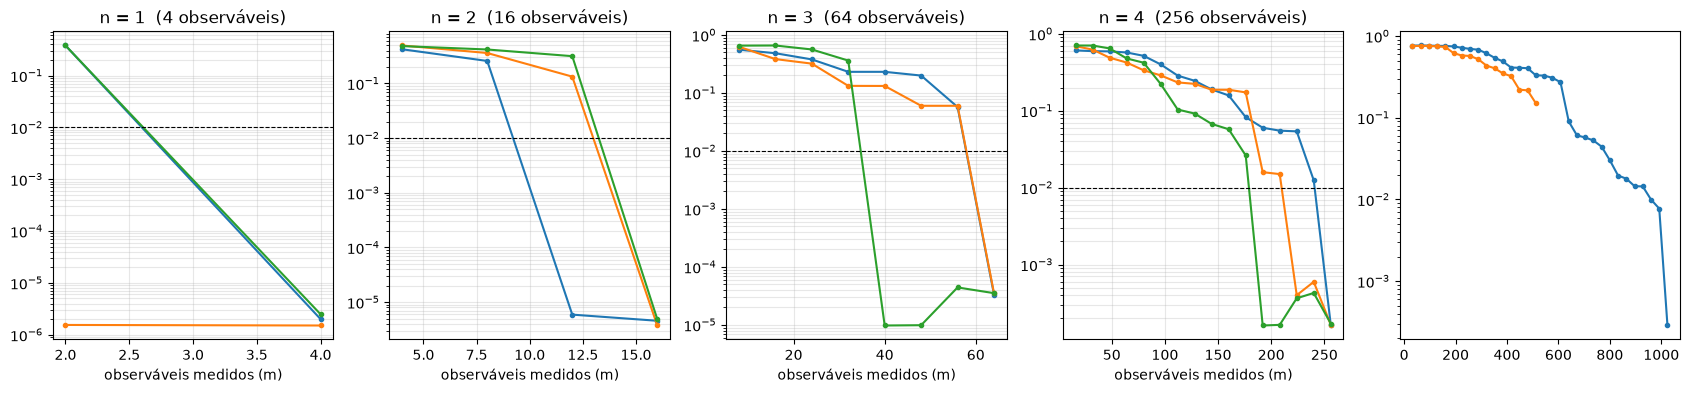

In [6]:
# ---------------------------------------------------------------------
# 5) Gráfico: distância ao alvo x número de observáveis, um painel por n
# ---------------------------------------------------------------------
fig, axs = plt.subplots(1, len(n_list), figsize=(4.2 * len(n_list), 4))
axs = np.atleast_1d(axs)      # garante lista de eixos mesmo com um único n
for ax, n in zip(axs, n_list):
    for seed in seeds:
        ms, dists = zip(*resultados[(n, seed)])
        ax.semilogy(ms, dists, "o-", ms=3, label=f"seed {seed}")
    ax.axhline(limiar, color="k", ls="--", lw=0.8)
    ax.set_title(f"n = {n}  ({4**n} observáveis)")
    ax.set_xlabel("observáveis medidos (m)")
    ax.grid(alpha=0.3, which="both")
axs[0].set_ylabel("distância de traço ao alvo")
axs[0].legend()
fig.tight_layout()
plt.show()

Agora, vamos usar o qutip para alguma visualização legal, não sei ainda oq fazer

In [ ]:
# Célula opcional: requer QuTiP 5.x.
# Caso não esteja instalado no ambiente: %pip install qutip

try:
    import qutip as qtp
    from qutip.wigner import wigner_transform

    def wigner_dois_qubits(rho, steps=100):

        # Garantimos que rho seja hermitiana
        rho = np.asarray(rho, dtype=complex)
        rho = (rho + rho.conj().T) / 2

        # Decomposição espectral
        valores, vetores = np.linalg.eigh(rho)

        # Pequenas correções numéricas
        valores = np.clip(valores, 0, None)
        valores = valores / np.sum(valores)

        # Inicializamos a função de Wigner
        W = np.zeros((steps, steps))

        for valor, vetor in zip(valores, vetores.T):

            if valor > 1e-12:

                # Construímos um ket de dois qubits
                psi = qtp.Qobj(
                    vetor.reshape(4, 1),
                    dims=[[2, 2], [1, 1]]
                )

                # Calculamos a contribuição do estado puro
                W_puro = wigner_transform(
                    psi,
                    j=0.5,
                    fullparity=True,
                    steps=steps,
                    slicearray=["l", "l"]
                )

                # Somamos com o peso correspondente
                W += valor * W_puro

        return W

    W_bell = wigner_dois_qubits(bell.rho)
    W_reg = wigner_dois_qubits(rho_incompleto)

    vmax = max(np.max(np.abs(W_bell)), np.max(np.abs(W_reg)))
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))

    im0 = ax[0].imshow(
        W_bell, origin="lower", extent=[0, 2*np.pi, 0, np.pi],
        aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
    )
    ax[0].set_title("Estado Bell")
    ax[0].set_xlabel(r"$\phi$")
    ax[0].set_ylabel(r"$\theta$")

    im1 = ax[1].imshow(
        W_reg, origin="lower", extent=[0, 2*np.pi, 0, np.pi],
        aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax
    )
    ax[1].set_title("Estado escolhido pela regularização")
    ax[1].set_xlabel(r"$\phi$")
    ax[1].set_ylabel(r"$\theta$")

    fig.colorbar(im1, ax=ax, label="Wigner")
    plt.tight_layout()
    plt.show()

except ImportError:
    print("QuTiP não está instalado. Execute %pip install qutip e rode esta célula novamente.")